## Section 1.3 - Automated Model

### Task 1 - Running simple logistic regression models

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path

# Προσοχή: Βεβαιώσου ότι το path είναι σωστό για τον υπολογιστή σου
DATASET123 = pd.read_csv("DATASET.csv")
DATASET123.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate,age_at_diagnosis,age_at_metastasis,monocyte,...,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention,test_result20,test_result100,PC1,PC2,PC3
0,1,1,1,2017-03-16,0,NaN,1935-01-01,82.203970,NaN,46.14,...,0,0,0,1,0,1,1,-1.205222,-0.355442,-0.515687
1,2,2,0,2005-03-31,0,NaN,1942-01-01,63.244353,NaN,50.14,...,0,0,0,0,0,0,0,-0.507886,-1.418185,1.097049
2,3,2,0,2017-08-08,0,NaN,1959-01-01,58.600958,NaN,49.86,...,0,0,0,1,0,0,0,0.808393,-0.195869,0.597930
3,4,2,0,2008-01-02,0,NaN,1934-02-01,73.916496,NaN,49.57,...,0,0,0,0,0,0,0,-0.301166,-0.571948,0.478331
4,5,2,0,2006-05-08,0,NaN,1949-03-01,57.185489,NaN,57.00,...,0,0,0,0,0,0,0,2.483636,0.119847,-0.410740


In [2]:
model = smf.logit(
 "metastasis ~ urinary_retention",
 data=DATASET123
).fit()

Optimization terminated successfully.
         Current function value: 0.636476
         Iterations 5


In [3]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:             metastasis   No. Observations:                 1159
Model:                          Logit   Df Residuals:                     1157
Method:                           MLE   Df Model:                            1
Date:                Wed, 05 Aug 2026   Pseudo R-squ.:                 0.02867
Time:                        16:49:13   Log-Likelihood:                -737.68
converged:                       True   LL-Null:                       -759.45
Covariance Type:            nonrobust   LLR p-value:                 4.139e-11
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -0.8080      0.074    -10.981      0.000      -0.952      -0.664
urinary_retention     0.9105      0.138      6.588      0.000       0.640       1.181
=====================================================================================
"""

In [4]:
model.params

Intercept           -0.808013
urinary_retention    0.910492
dtype: float64

In [5]:
model.pvalues

Intercept            4.734564e-28
urinary_retention    4.468372e-11
dtype: float64

In [6]:
model.aic

np.float64(1479.3504774323676)

In [7]:
DATASET123["Predicted_probability"] = model.predict(DATASET123)
DATASET123[
["metastasis",
"urinary_retention",
"Predicted_probability"]
].head()

,metastasis,urinary_retention,Predicted_probability
0,0,0,0.308314
1,0,0,0.308314
2,0,0,0.308314
3,0,0,0.308314
4,0,0,0.308314


### Task 2 - Running Multiple Logistic Regression Models

Build a full multivariable logistic regression model using all meaningful predictors.
We will exclude:

- principal components (PC1, PC2, PC3)

- variables that do not make sense in a regression model (ID, dates, etc.)

Check whether the model fulfills the assumptions of logistic regression, focusing on:

- Multicollinearity, using the Variance Inflation Factor (VIF)

- Model fit statistics

- Coefficient interpretation (odds ratios)

Evaluate whether replacing biomarkers with principal components reduces collinearity.

In [8]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv("DATASET.csv")

# Variables to drop
drop_vars = [
    "PC1", "PC2", "PC3",
    "ID", "birthdate", "date_met",
    "prostdtfirst", "age_at_metastasis",
    "civil_status", "test_results20", "test_results_100"
]
df = df.drop(columns=drop_vars, errors="ignore")
y = df["metastasis"].astype(int)
X = df.drop(columns=["metastasis"])

X_const = sm.add_constant(X)
model_full = sm.Logit(y, X_const).fit()
model_full.summary()

Optimization terminated successfully.
         Current function value: 0.445801
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:             metastasis   No. Observations:                 1159
Model:                          Logit   Df Residuals:                     1138
Method:                           MLE   Df Model:                           20
Date:                Wed, 05 Aug 2026   Pseudo R-squ.:                  0.3197
Time:                        16:49:16   Log-Likelihood:                -516.68
converged:                       True   LL-Null:                       -759.45
Covariance Type:            nonrobust   LLR p-value:                 3.103e-90
=========================================================================================
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -8.3830      1.355     -6.186      0.000     -11.039      -5.727
cancer_family             2.1928      0.183     12.004      0.000       1.835       2.551
age_at_diagnosis          0.0504      0.011      4.768      0.000       0.030       0.071
monocyte                  0.0383      0.019      2.007      0.045       0.001       0.076
urea                     -0.2655      0.134     -1.976      0.048      -0.529      -0.002
lymphocyte                0.0224      0.006      3.899      0.000       0.011       0.034
thrombocyte              -0.0058      0.007     -0.799      0.424      -0.020       0.008
erythrocyte              -0.0044      0.003     -1.282      0.200      -0.011       0.002
albumin                   0.0227      0.011      2.007      0.045       0.001       0.045
creatinine               -2.4117      2.348     -1.027      0.304      -7.013       2.190
globulin                  0.0585      0.062      0.938      0.348      -0.064       0.181
psa                       0.0003      0.000      2.119      0.034    2.52e-05       0.001
coag_factor               0.0094      0.031      0.303      0.762      -0.051       0.070
diabetes                 -1.1363      0.254     -4.481      0.000      -1.633      -0.639
hearing_loss             -0.1662      0.212     -0.785      0.433      -0.581       0.249
hypercholesterolaemia    -0.1537      0.251     -0.611      0.541      -0.647       0.339
hypertension              0.4346      0.210      2.066      0.039       0.022       0.847
osteoporosis              0.7563      0.181      4.172      0.000       0.401       1.112
urinary_retention         0.8537      0.180      4.751      0.000       0.502       1.206
test_result20             0.5741      0.187      3.064      0.002       0.207       0.941
test_result100            0.3190      0.249      1.280      0.201      -0.169       0.808
=========================================================================================
"""

This function produces a clean table containing:
- Coefficients
- Standard errors
- z‑values
- p‑values
- Odds ratios
- 95% confidence intervals

This is essential for interpreting logistic regression results.

In [9]:
def odds_ratio_table(model):
    conf = model.conf_int()
    conf.columns = ["2.5%", "97.5%"]
    
    table = pd.DataFrame({
        "Coefficient": model.params,
        "Std. Error": model.bse,
        "z value": model.tvalues,
        "p value": model.pvalues,
        "Odds Ratio": np.exp(model.params),
        "OR 2.5%": np.exp(conf["2.5%"]),
        "OR 97.5%": np.exp(conf["97.5%"])
    })
    
    return table

odds_ratio_table(model_full)


,Coefficient,Std. Error,z value,p value,Odds Ratio,OR 2.5%,OR 97.5%
const,-8.383014,1.355231,-6.185670,6.183935e-10,0.000229,0.000016,0.003257
cancer_family,2.192758,0.182675,12.003631,3.400442e-33,8.959889,6.263395,12.817269
age_at_diagnosis,0.050382,0.010566,4.768129,1.859451e-06,1.051672,1.030117,1.073679
monocyte,0.038334,0.019099,2.007068,4.474241e-02,1.039078,1.000900,1.078712
urea,-0.265510,0.134378,-1.975836,4.817336e-02,0.766815,0.589261,0.997869
lymphocyte,0.022416,0.005749,3.899233,9.649773e-05,1.022670,1.011211,1.034258
thrombocyte,-0.005817,0.007279,-0.799219,4.241635e-01,0.994200,0.980117,1.008485
erythrocyte,-0.004374,0.003412,-1.281818,1.999065e-01,0.995636,0.989000,1.002317
albumin,0.022740,0.011330,2.007093,4.473976e-02,1.023001,1.000534,1.045972
creatinine,-2.411725,2.347708,-1.027268,3.042943e-01,0.089660,0.000900,8.932514


##### Model Fit Statistics Function
This function extracts:
- AIC
- BIC
- Log‑likelihood
- Pseudo‑R²
- Degrees of freedom
These help evaluate how well the model fits the data.

In [10]:
def model_fit_statistics(model, model_name):
    return pd.DataFrame({
        "Model": [model_name],
        "AIC": [model.aic],
        "BIC": [model.bic],
        "Log-Likelihood": [model.llf],
        "Pseudo R2": [model.prsquared],
        "DF Model": [model.df_model],
        "DF Residuals": [model.df_resid]
    })

model_fit_statistics(model_full, "Full Logistic Regression")

,Model,AIC,BIC,Log-Likelihood,Pseudo R2,DF Model,DF Residuals
0,Full Logistic Regression,1075.367376,1181.528946,-516.683688,0.319659,20.0,1138.0


##### VIF Fynction

In [11]:
def calculate_vif(data, variables):
    X = data[variables].copy()
    X = X.apply(pd.to_numeric, errors="coerce")
    X = X.dropna()
    
    X_const = sm.add_constant(X)
    
    vif_table = pd.DataFrame({
        "Variable": X_const.columns,
        "VIF": [
            variance_inflation_factor(X_const.values, i)
            for i in range(X_const.shape[1])
        ]
    })
    
    return vif_table.sort_values("VIF", ascending=False)

vif_results = calculate_vif(df, X.columns)
vif_results

,Variable,VIF
0,const,284.306012
9,creatinine,63.347068
8,albumin,35.345014
12,coag_factor,14.676545
10,globulin,6.613874
6,thrombocyte,5.342671
7,erythrocyte,4.737896
3,monocyte,2.053497
20,test_result100,1.835811
4,urea,1.700436


Optimization terminated successfully.
         Current function value: 0.636476
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:             metastasis   No. Observations:                 1159
Model:                          Logit   Df Residuals:                     1157
Method:                           MLE   Df Model:                            1
Date:                Wed, 05 Aug 2026   Pseudo R-squ.:                 0.02867
Time:                        16:49:22   Log-Likelihood:                -737.68
converged:                       True   LL-Null:                       -759.45
Covariance Type:            nonrobust   LLR p-value:                 4.139e-11
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -0.8080      0.074    -10.981      0.000      -0.952      -0.664
urinary_

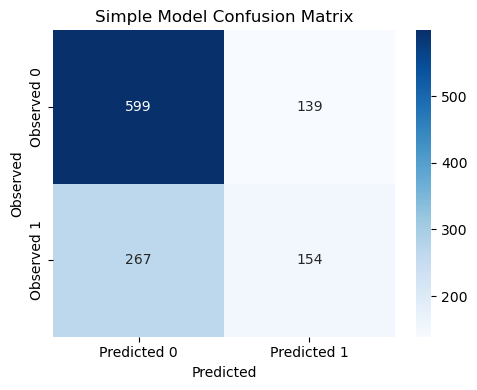

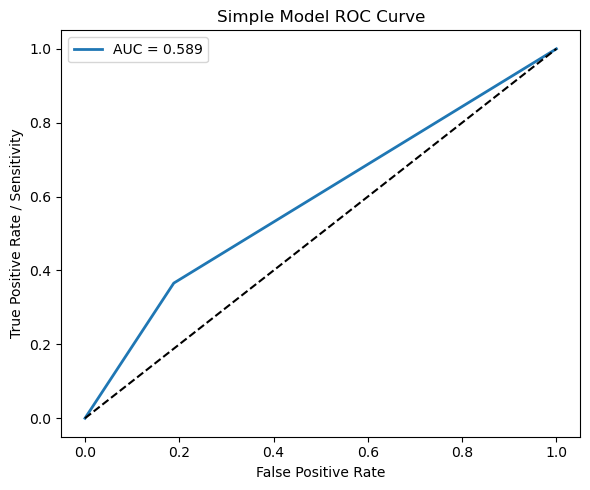

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.69      0.81      0.75       738
           1       0.53      0.37      0.43       421

    accuracy                           0.65      1159
   macro avg       0.61      0.59      0.59      1159
weighted avg       0.63      0.65      0.63      1159



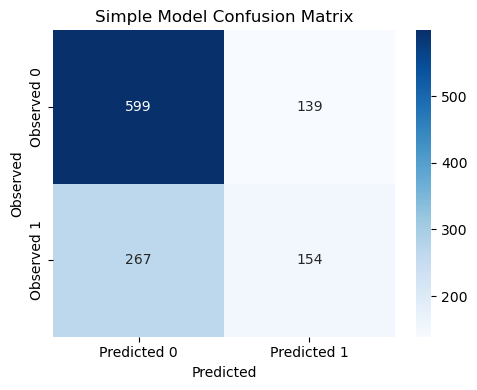

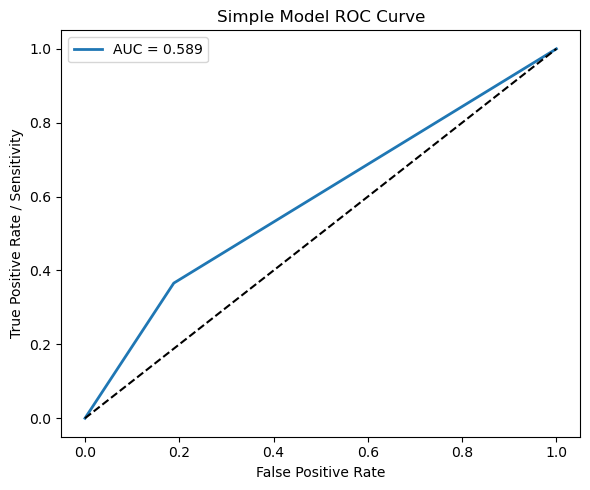

              precision    recall  f1-score   support

           0       0.69      0.81      0.75       738
           1       0.53      0.37      0.43       421

    accuracy                           0.65      1159
   macro avg       0.61      0.59      0.59      1159
weighted avg       0.63      0.65      0.63      1159



In [12]:
DATASET123["Predicted_class"] = np.where(DATASET123["Predicted_probability"]>=0.50, 1, 0)
DATASET123[["metastasis","Predicted_probability","Predicted_class"]
].head()

def plot_confusion_matrix(cm_df, title):

 #Plot confusion matrix heatmap.

 plt.figure(figsize=(5, 4))
 sns.heatmap(
 cm_df,
 annot=True,
 fmt="d",
 cmap="Blues"
 )
 plt.title(title)
 plt.ylabel("Observed")
 plt.xlabel("Predicted")
 plt.tight_layout()
 plt.show()

def plot_roc_curve(model, data, outcome_col, title):
    y_true = data[outcome_col].astype(int)
    
    # Σημείωση: Στις ROC curves συνήθως χρησιμοποιούμε predict_proba αντί για predict
    probabilities = model.predict(data) 
    
    fpr, tpr, thresholds = roc_curve(y_true, probabilities)
    auc_value = roc_auc_score(y_true, probabilities)
    
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_value:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="black")
    
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate / Sensitivity")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

model = smf.logit("metastasis ~ urinary_retention", data=DATASET123).fit()
print(model.summary())

DATASET123["Predicted_probability"] = model.predict(DATASET123)
DATASET123["Predicted_class"] = np.where(DATASET123["Predicted_probability"]>=0.50, 1, 0)


cm = confusion_matrix(DATASET123["metastasis"], DATASET123["Predicted_class"])
cm_df = pd.DataFrame(cm, index=["Observed 0", "Observed 1"], columns=["Predicted 0", "Predicted 1"])
plot_confusion_matrix(cm_df, "Simple Model Confusion Matrix")


plot_roc_curve(model=model, data=DATASET123, outcome_col="metastasis", title="Simple Model ROC Curve")

print("--- Classification Report ---")
print(classification_report(DATASET123["metastasis"], DATASET123["Predicted_class"]))

def plot_confusion_matrix(cm_df, title):
    """Plot confusion matrix heatmap."""
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
    plt.title(title)
    plt.ylabel("Observed")
    plt.xlabel("Predicted")
    plt.tight_layout()
    plt.show()

def plot_roc_curve(model, data, outcome_col, title):
    """Plot ROC curve."""
    y_true = data[outcome_col].astype(int)
    probabilities = model.predict(data) 
    
    fpr, tpr, thresholds = roc_curve(y_true, probabilities)
    auc_value = roc_auc_score(y_true, probabilities)
    
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_value:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="black")
    
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate / Sensitivity")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

cm = confusion_matrix(
    DATASET123["metastasis"],
    DATASET123["Predicted_class"]
)

cm_df = pd.DataFrame(cm, index=["Observed 0", "Observed 1"], columns=["Predicted 0", "Predicted 1"])

plot_confusion_matrix(cm_df, "Simple Model Confusion Matrix")

plot_roc_curve(model=model, data=DATASET123, outcome_col="metastasis", title="Simple Model ROC Curve")

print(classification_report(
    DATASET123["metastasis"],
    DATASET123["Predicted_class"]
))

In [13]:
def odds_ratio_table(model):
    """Create coefficient, odds ratio, CI and p-value table."""
    conf = model.conf_int()
    conf.columns = ["2.5%", "97.5%"]
    table = pd.DataFrame({
        "Coefficient": model.params,
        "Std. Error": model.bse,
        "z value": model.tvalues,
        "p value": model.pvalues,
        "Odds Ratio": np.exp(model.params),
        "OR 2.5%": np.exp(conf["2.5%"]),
        "OR 97.5%": np.exp(conf["97.5%"])
    })
    return table


def model_fit_statistics(model, model_name):
    """
    Extract model-level fit statistics.
    """
    return pd.DataFrame({
        "Model": [model_name],
        "AIC": [model.aic],
        "BIC": [model.bic],
        "Log-Likelihood": [model.llf],
        "Pseudo R2": [model.prsquared],
        "DF Model": [model.df_model],
        "DF Residuals": [model.df_resid]
    })


def calculate_vif(data, variables):
    """Calculate Variance Inflation Factor (VIF)."""
    X = data[variables].copy()
    X = X.apply(pd.to_numeric, errors="coerce")
    X = X.dropna()
    X_const = sm.add_constant(X)
    
    vif_table = pd.DataFrame({
        "Variable": X_const.columns,
        "VIF": [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
    })
    return vif_table.sort_values("VIF", ascending=False)

# Δημιουργούμε μια λίστα με τις μεταβλητές που θέλουμε να ελέγξουμε για πολυσυγγραμμικότητα (VIF)
check_vars = ["urinary_retention", "psa", "creatinine", "civil_status", "age_at_diagnosis"] 

# Φιλτράρισμα για να σιγουρευτούμε ότι υπάρχουν στο dataset
check_vars = [v for v in check_vars if v in DATASET123.columns]

# Υπολογισμός και εμφάνιση του VIF
vif_results = calculate_vif(DATASET123, check_vars)
print("--- Variance Inflation Factor (VIF) Results ---")
display(vif_results)

--- Variance Inflation Factor (VIF) Results ---


,Variable,VIF
0,const,99.662632
4,civil_status,1.097542
5,age_at_diagnosis,1.087581
3,creatinine,1.051673
2,psa,1.048244
1,urinary_retention,1.033317


##### Does replacing biomarkers with principal components reduce VIF?

In [32]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("DATASET.csv")

# These were the top 3:
columns = [
    "monocyte", "urea", "lymphocyte", "thrombocyte", "erythrocyte", "globulin", "psa", "PC1", "PC2", "PC3",
    "age_at_diagnosis", "cancer_family", "hearing_loss", "hypertension", "urinary_retention", "diabetes", "hypercholesterolaemia", "osteoporosis"
]
X = df[columns].copy()
X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna()

# Assuming a hypothetical binary target column named 'target' exists in DATASET123
# Replace 'target' with your actual dependent variable column name
y = df['metastasis']

# 2. Run Logistic Regression using statsmodels
# Add a constant (intercept) for statsmodels GLM/Logit
X_sm = sm.add_constant(X)

logit_model = sm.Logit(y, X_sm)
logit_result = logit_model.fit()
print(logit_result.summary())

vif_results = calculate_vif(df, X.columns)
vif_results


Optimization terminated successfully.
         Current function value: 0.453867
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:             metastasis   No. Observations:                 1159
Model:                          Logit   Df Residuals:                     1140
Method:                           MLE   Df Model:                           18
Date:                Wed, 05 Aug 2026   Pseudo R-squ.:                  0.3074
Time:                        17:16:19   Log-Likelihood:                -526.03
converged:                       True   LL-Null:                       -759.45
Covariance Type:            nonrobust   LLR p-value:                 9.616e-88
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                  -148.4323     90.826     -1.634      0.102    -326.448      29.

,Variable,VIF
0,const,1.203565e+06
8,PC1,2.534003e+04
10,PC3,1.320108e+04
9,PC2,5.692109e+03
5,erythrocyte,5.262312e+03
4,thrombocyte,5.051689e+03
7,psa,4.033109e+03
6,globulin,2.853060e+03
1,monocyte,2.690481e+03
3,lymphocyte,1.000205e+03


#### Improved Model

--- Results per Fold ---


,Fold,Accuracy,Sensitivity,Specificity,Precision,F1-score,AUC
0,Fold1,0.784483,0.714286,0.824324,0.697674,0.705882,0.835907
1,Fold2,0.767241,0.619048,0.851351,0.702703,0.658228,0.840090
2,Fold3,0.793103,0.690476,0.851351,0.725000,0.707317,0.857786
3,Fold4,0.741379,0.571429,0.837838,0.666667,0.615385,0.837516
4,Fold5,0.793103,0.666667,0.864865,0.736842,0.700000,0.862291
5,Fold6,0.767241,0.714286,0.797297,0.666667,0.689655,0.863256
6,Fold7,0.818966,0.690476,0.891892,0.783784,0.734177,0.905405
7,Fold8,0.793103,0.666667,0.864865,0.736842,0.700000,0.795367
8,Fold9,0.767241,0.558140,0.890411,0.750000,0.640000,0.839758
9,Fold10,0.782609,0.761905,0.794521,0.680851,0.719101,0.841161



--- Average Performance ---


Accuracy       0.780847
Sensitivity    0.665338
Specificity    0.846872
Precision      0.714703
F1-score       0.686975
AUC            0.847854
dtype: float64

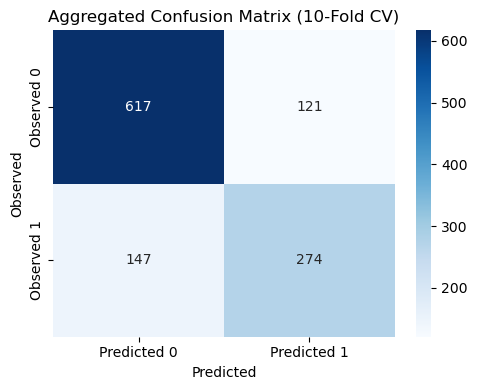

In [39]:
df = pd.read_csv("DATASET.csv")

# Drop principal components + your extra columns
df = df.drop(columns=[
    "PC1", "PC2", "PC3",
    "ID", "birthdate", "date_met",
    "prostdtfirst", "age_at_metastasis",
    "civil_status", "test_result_100",
    "test_result_20", "test_result20",
    "test_result100", 
], errors="ignore")

y = df["metastasis"].astype(int)
X = df.drop(columns=["metastasis"])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)

logistic_cv_model = Pipeline(steps=[
    ("scaler", StandardScaler()), 
    ("model", LogisticRegression(max_iter=5000, solver="lbfgs"))
])

fold_results = []
all_predictions = []

for fold_number, (train_index, test_index) in enumerate(cv.split(X, y), start=1):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    logistic_cv_model.fit(X_train, y_train)

    y_pred = logistic_cv_model.predict(X_test)
    y_prob = logistic_cv_model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    sensitivity = recall_score(y_test, y_pred, pos_label=1)
    specificity = recall_score(y_test, y_pred, pos_label=0)
    precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label=1)

    try:
        auc = roc_auc_score(y_test, y_prob)
    except ValueError:
        auc = np.nan

    fold_results.append({
        "Fold": f"Fold{fold_number}",
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1-score": f1,
        "AUC": auc
    })

    fold_pred_df = pd.DataFrame({
        "Row_index": test_index,
        "Observed": y_test.values,
        "Predicted": y_pred,
        "Predicted_probability": y_prob,
        "Fold": f"Fold{fold_number}"
    })

    all_predictions.append(fold_pred_df)

results_df = pd.DataFrame(fold_results)

print("--- Results per Fold ---")
display(results_df)

print("\n--- Average Performance ---")
display(results_df.mean(numeric_only=True))

cm = confusion_matrix(all_true, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=["Observed 0", "Observed 1"],
    columns=["Predicted 0", "Predicted 1"]
)

plot_confusion_matrix(cm_df, title="Aggregated Confusion Matrix (10-Fold CV)")


# Logistic Regression with RFE + 5-fold CV

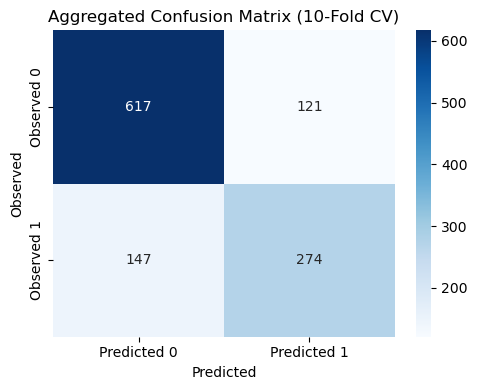


CLASSIFICATION REPORT (Aggregated 10-Fold CV)
              precision    recall  f1-score   support

           0       0.81      0.84      0.82       738
           1       0.69      0.65      0.67       421

    accuracy                           0.77      1159
   macro avg       0.75      0.74      0.75      1159
weighted avg       0.77      0.77      0.77      1159



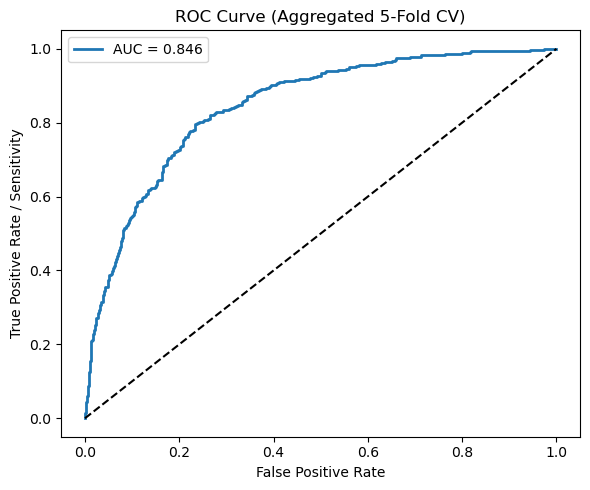

In [34]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

# ---------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------
df = pd.read_csv("DATASET.csv")

# Drop principal components + your extra columns
df = df.drop(columns=[
    "PC1", "PC2", "PC3",
    "ID", "birthdate", "date_met",
    "prostdtfirst", "age_at_metastasis",
    "civil_status"
], errors="ignore")

y = df["metastasis"].astype(int)
X = df.drop(columns=["metastasis"])

# ---------------------------------------------------------
# 2. SET UP 5-FOLD CV
# ---------------------------------------------------------
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

all_true = []
all_probs = []
all_preds = []

# ---------------------------------------------------------
# 3. CROSS-VALIDATION LOOP (with scaling)
# ---------------------------------------------------------
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # --- SCALE TRAINING DATA ---
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Convert back to DataFrame to keep column names
    X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
    X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

    # --- RFE on scaled training fold only ---
    base_logreg = LogisticRegression(max_iter=1000, solver="liblinear")
    selector = RFE(base_logreg, n_features_to_select=10)
    selector = selector.fit(X_train_scaled, y_train)

    selected_features = X_train.columns[selector.support_]

    # --- Fit logistic regression on selected scaled features ---
    model = LogisticRegression(max_iter=1000, solver="liblinear")
    model.fit(X_train_scaled[selected_features], y_train)

    # --- Predict on scaled test fold ---
    probs = model.predict_proba(X_test_scaled[selected_features])[:, 1]
    preds = (probs >= 0.5).astype(int)

    # --- Store predictions ---
    all_true.extend(y_test.tolist())
    all_probs.extend(probs.tolist())
    all_preds.extend(preds.tolist())

# ---------------------------------------------------------
# 4. AGGREGATED CONFUSION MATRIX
# ---------------------------------------------------------
cm = confusion_matrix(all_true, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=["Observed 0", "Observed 1"],
    columns=["Predicted 0", "Predicted 1"]
)

plot_confusion_matrix(cm_df, title="Aggregated Confusion Matrix (10-Fold CV)")

# ---------------------------------------------------------
# 5. AGGREGATED CLASSIFICATION REPORT
# ---------------------------------------------------------
print("\nCLASSIFICATION REPORT (Aggregated 10-Fold CV)")
print(classification_report(all_true, all_preds))

# ---------------------------------------------------------
# 6. AGGREGATED ROC CURVE
# ---------------------------------------------------------
fpr, tpr, thresholds = roc_curve(all_true, all_probs)
auc_value = roc_auc_score(all_true, all_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Sensitivity")
plt.title("ROC Curve (Aggregated 5-Fold CV)")
plt.legend()
plt.tight_layout()
plt.show()


#### Random forest with RFE + 5-fold cross-validation

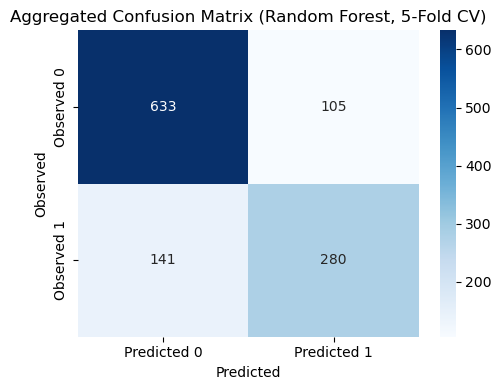


CLASSIFICATION REPORT (Aggregated 5-Fold CV)
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       738
           1       0.73      0.67      0.69       421

    accuracy                           0.79      1159
   macro avg       0.77      0.76      0.77      1159
weighted avg       0.78      0.79      0.79      1159



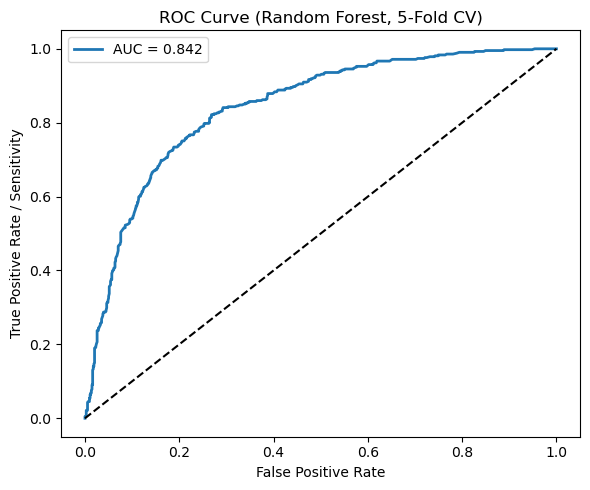

In [32]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

# ---------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------
df = pd.read_csv("DATASET.csv")

# Drop principal components + your extra columns
df = df.drop(columns=[
    "PC1", "PC2", "PC3",
    "ID", "birthdate", "date_met",
    "prostdtfirst", "age_at_metastasis",
    "civil_status"
], errors="ignore")

y = df["metastasis"].astype(int)
X = df.drop(columns=["metastasis"])

# ---------------------------------------------------------
# 2. SET UP 5-FOLD CV
# ---------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

all_true = []
all_probs = []
all_preds = []

# ---------------------------------------------------------
# 3. CROSS-VALIDATION LOOP (Random Forest)
# ---------------------------------------------------------
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # --- Train Random Forest ---
    model = RandomForestClassifier(
        n_estimators=800,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    # --- Predict on test fold ---
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.5).astype(int)

    # --- Store predictions ---
    all_true.extend(y_test.tolist())
    all_probs.extend(probs.tolist())
    all_preds.extend(preds.tolist())

# ---------------------------------------------------------
# 4. AGGREGATED CONFUSION MATRIX
# ---------------------------------------------------------
cm = confusion_matrix(all_true, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=["Observed 0", "Observed 1"],
    columns=["Predicted 0", "Predicted 1"]
)

plot_confusion_matrix(cm_df, title="Aggregated Confusion Matrix (Random Forest, 5-Fold CV)")

# ---------------------------------------------------------
# 5. AGGREGATED CLASSIFICATION REPORT
# ---------------------------------------------------------
print("\nCLASSIFICATION REPORT (Aggregated 5-Fold CV)")
print(classification_report(all_true, all_preds))

# ---------------------------------------------------------
# 6. AGGREGATED ROC CURVE
# ---------------------------------------------------------
fpr, tpr, thresholds = roc_curve(all_true, all_probs)
auc_value = roc_auc_score(all_true, all_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Sensitivity")
plt.title("ROC Curve (Random Forest, 5-Fold CV)")
plt.legend()
plt.tight_layout()
plt.show()


#### SVM with RBF kernel, RFE and 5-fold validation

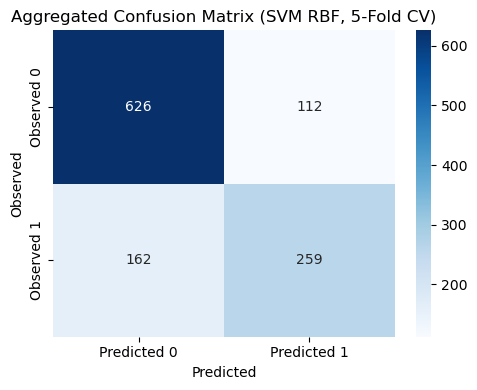


CLASSIFICATION REPORT (Aggregated 5-Fold CV)
              precision    recall  f1-score   support

           0       0.79      0.85      0.82       738
           1       0.70      0.62      0.65       421

    accuracy                           0.76      1159
   macro avg       0.75      0.73      0.74      1159
weighted avg       0.76      0.76      0.76      1159



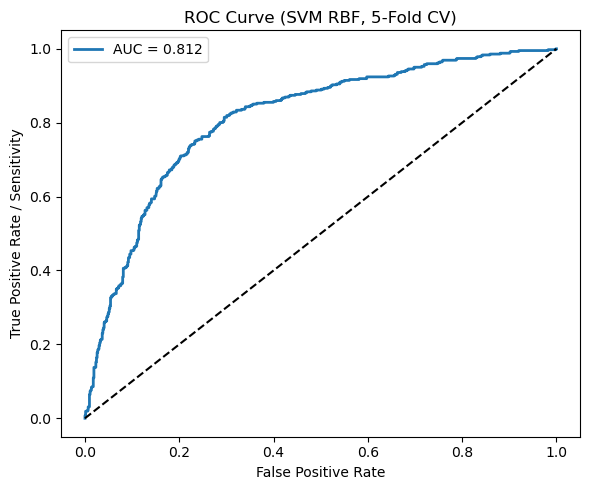

In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

# ---------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------
df = pd.read_csv("DATASET.csv")

# Drop principal components + your extra columns
df = df.drop(columns=[
    "PC1", "PC2", "PC3",
    "ID", "birthdate", "date_met",
    "prostdtfirst", "age_at_metastasis",
    "civil_status"
], errors="ignore")

y = df["metastasis"].astype(int)
X = df.drop(columns=["metastasis"])

# ---------------------------------------------------------
# 2. SET UP 5-FOLD CV
# ---------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

all_true = []
all_probs = []
all_preds = []

# ---------------------------------------------------------
# 3. CROSS-VALIDATION LOOP (SVM RBF)
# ---------------------------------------------------------
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # --- SCALE TRAINING DATA ---
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # --- Train SVM (RBF kernel) ---
    model = SVC(
        kernel="rbf",
        probability=True,   # needed for ROC curve
        C=2.0,
        gamma="auto",
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    # --- Predict on test fold ---
    probs = model.predict_proba(X_test_scaled)[:, 1]
    preds = (probs >= 0.5).astype(int)

    # --- Store predictions ---
    all_true.extend(y_test.tolist())
    all_probs.extend(probs.tolist())
    all_preds.extend(preds.tolist())

# ---------------------------------------------------------
# 4. AGGREGATED CONFUSION MATRIX
# ---------------------------------------------------------
cm = confusion_matrix(all_true, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=["Observed 0", "Observed 1"],
    columns=["Predicted 0", "Predicted 1"]
)

plot_confusion_matrix(cm_df, title="Aggregated Confusion Matrix (SVM RBF, 5-Fold CV)")

# ---------------------------------------------------------
# 5. AGGREGATED CLASSIFICATION REPORT
# ---------------------------------------------------------
print("\nCLASSIFICATION REPORT (Aggregated 5-Fold CV)")
print(classification_report(all_true, all_preds))

# ---------------------------------------------------------
# 6. AGGREGATED ROC CURVE
# ---------------------------------------------------------
fpr, tpr, thresholds = roc_curve(all_true, all_probs)
auc_value = roc_auc_score(all_true, all_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Sensitivity")
plt.title("ROC Curve (SVM RBF, 5-Fold CV)")
plt.legend()
plt.tight_layout()
plt.show()


### Task 5 - Comparison with other classifiers

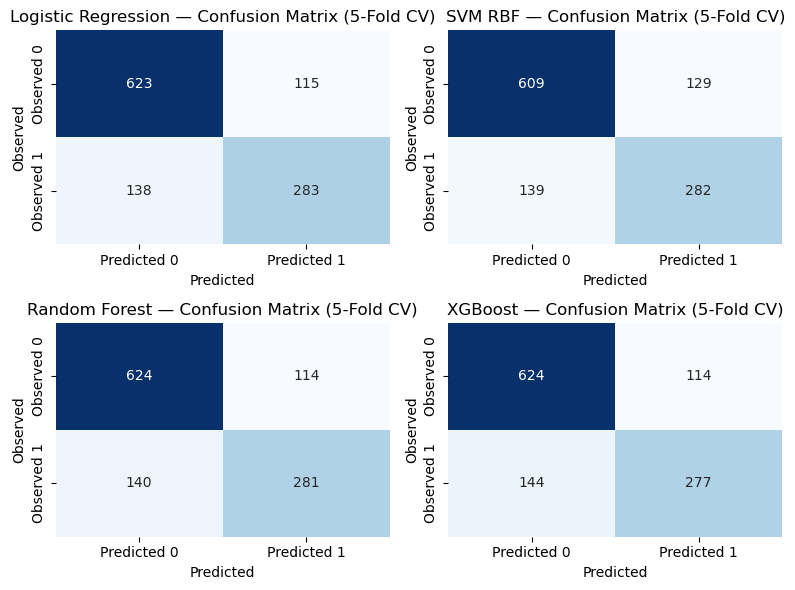

,Model,Accuracy,Sensitivity,Specificity,F1-score,AUC
0,Logistic Regression,0.7886,0.6722,0.8550,0.6979,0.8393
1,SVM RBF,0.7645,0.6580,0.8252,0.6699,0.8153
2,Random Forest,0.7826,0.6627,0.8509,0.6889,0.8372
3,XGBoost,0.7731,0.6461,0.8455,0.6741,0.8334


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, roc_auc_score, recall_score
from xgboost import XGBClassifier

# ---------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------
df = pd.read_csv("DATASET.csv")

# Drop principal components + your extra columns
df = df.drop(columns=[
    "PC1", "PC2", "PC3",
    "ID", "birthdate", "date_met",
    "prostdtfirst", "age_at_metastasis",
    "civil_status", "test_result_100",
    "test_result_20", "test_result20",
    "test_result100"
], errors="ignore")

y = df["metastasis"].astype(int)
X = df.drop(columns=["metastasis"])

# ---------------------------------------------------------
# 2. SET UP 5-FOLD CV
# ---------------------------------------------------------
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Storage for results
results = {
    "Logistic Regression": {"true": [], "pred": [], "proba": [], "features": []},
    "SVM RBF": {"true": [], "pred": [], "proba": []},
    "Random Forest": {"true": [], "pred": [], "proba": []},
    "XGBoost": {"true": [], "pred": [], "proba": []}
}

# ---------------------------------------------------------
# 3. CROSS-VALIDATION LOOP
# ---------------------------------------------------------
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # =====================================================
    # LOGISTIC REGRESSION (scaled + RFE)
    # =====================================================
    scaler_lr = StandardScaler()
    X_train_lr = scaler_lr.fit_transform(X_train)
    X_test_lr = scaler_lr.transform(X_test)

    X_train_lr = pd.DataFrame(X_train_lr, columns=X_train.columns, index=X_train.index)
    X_test_lr = pd.DataFrame(X_test_lr, columns=X_test.columns, index=X_test.index)

    base_lr = LogisticRegression(max_iter=1000, solver="liblinear")
    selector_lr = RFE(base_lr, n_features_to_select=10)
    selector_lr.fit(X_train_lr, y_train)

    selected_lr = X_train.columns[selector_lr.support_]
    results["Logistic Regression"]["features"].append(selected_lr.tolist())

    lr_model = LogisticRegression(max_iter=1000, solver="liblinear")
    lr_model.fit(X_train_lr[selected_lr], y_train)

    lr_preds = lr_model.predict(X_test_lr[selected_lr])
    lr_proba = lr_model.predict_proba(X_test_lr[selected_lr])[:, 1]

    results["Logistic Regression"]["true"].extend(y_test.tolist())
    results["Logistic Regression"]["pred"].extend(lr_preds.tolist())
    results["Logistic Regression"]["proba"].extend(lr_proba.tolist())

    # =====================================================
    # SVM (scaled, no RFE)
    # =====================================================
    scaler_svm = StandardScaler()
    X_train_svm = scaler_svm.fit_transform(X_train)
    X_test_svm = scaler_svm.transform(X_test)

    svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True)
    svm_model.fit(X_train_svm, y_train)

    svm_preds = svm_model.predict(X_test_svm)
    svm_proba = svm_model.predict_proba(X_test_svm)[:, 1]

    results["SVM RBF"]["true"].extend(y_test.tolist())
    results["SVM RBF"]["pred"].extend(svm_preds.tolist())
    results["SVM RBF"]["proba"].extend(svm_proba.tolist())

    # =====================================================
    # RANDOM FOREST (no scaling, no RFE)
    # =====================================================
    rf_model = RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    )
    rf_model.fit(X_train, y_train)

    rf_preds = rf_model.predict(X_test)
    rf_proba = rf_model.predict_proba(X_test)[:, 1]

    results["Random Forest"]["true"].extend(y_test.tolist())
    results["Random Forest"]["pred"].extend(rf_preds.tolist())
    results["Random Forest"]["proba"].extend(rf_proba.tolist())

    # =====================================================
    # XGBOOST (no scaling, no RFE)
    # =====================================================
    xgb_model = XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42
    )
    xgb_model.fit(X_train, y_train)

    xgb_preds = xgb_model.predict(X_test)
    xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

    results["XGBoost"]["true"].extend(y_test.tolist())
    results["XGBoost"]["pred"].extend(xgb_preds.tolist())
    results["XGBoost"]["proba"].extend(xgb_proba.tolist())

# ---------------------------------------------------------
# 4. PLOT 2X2 CONFUSION MATRICES & GENERATE COMPARISON TABLE
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
axes = axes.ravel()

metrics_summary = []

for idx, (model_name, data) in enumerate(results.items()):
    y_true = np.array(data["true"])
    y_pred = np.array(data["pred"])
    y_proba = np.array(data["proba"])

    # Compute metrics
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0  # Recall for class 1
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0  # Recall for class 0
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_proba)

    metrics_summary.append({
        "Model": model_name,
        "Accuracy": round(accuracy, 4),
        "Sensitivity": round(sensitivity, 4),
        "Specificity": round(specificity, 4),
        "F1-score": round(f1, 4),
        "AUC": round(auc, 4)
    })

    # Plot Confusion Matrix in 2x2 grid
    cm_df = pd.DataFrame(
        cm,
        index=["Observed 0", "Observed 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{model_name} — Confusion Matrix (5-Fold CV)")
    axes[idx].set_ylabel("Observed")
    axes[idx].set_xlabel("Predicted")

plt.tight_layout()
plt.show()

comparison_df

In [45]:
import pandas as pd

# Define the summary data
summary_data = [
    {
        "Model": "Logistic Regression",
        "Scaling Used": "Yes (StandardScaler)",
        "RFE Used": "Yes (Top 10 features)",
        "Additional Details": "Solver: liblinear"
    },
    {
        "Model": "SVM RBF",
        "Scaling Used": "Yes (StandardScaler)",
        "RFE Used": "No",
        "Additional Details": "Kernel: rbf, C=1.0, Probability=True"
    },
    {
        "Model": "Random Forest",
        "Scaling Used": "No",
        "RFE Used": "No",
        "Additional Details": "500 estimators"
    },
    {
        "Model": "XGBoost",
        "Scaling Used": "No",
        "RFE Used": "No",
        "Additional Details": "300 estimators, learning rate=0.05"
    }
]

# Convert to a pandas DataFrame
model_summary_df = pd.DataFrame(summary_data)

# Display the dataframe cleanly in Jupyter Notebook
display(model_summary_df)

,Model,Scaling Used,RFE Used,Additional Details
0,Logistic Regression,Yes (StandardScaler),Yes (Top 10 features),Solver: liblinear
1,SVM RBF,Yes (StandardScaler),No,"Kernel: rbf, C=1.0, Probability=True"
2,Random Forest,No,No,500 estimators
3,XGBoost,No,No,"300 estimators, learning rate=0.05"
